# 2.2 Entrenamiento y ajuste de hiperparámetros: análisis

Análisis de las corridas de la Actividad 2.2, entrenadas en la A100 de Colab con `nube/2.2_entrenamiento_colab.ipynb` según el diseño de `docs/plan_oe2.md`. Este notebook no entrena: incorpora las descargas de cada fase, aplica las reglas de decisión de `comun_oe2` y genera las figuras.

| Fase | Qué compara | Regla, fijada antes de entrenar |
| :--- | :--- | :--- |
| **0. Fondos negativos** | La referencia con y sin fondos, 2 modelos × 3 semillas | Se adoptan si, en los dos modelos, los falsos positivos sobre las impurezas de `valid` bajan al menos un 90 % y el mAP50-95 en los granos no baja más de 0.005 |
| **1. Cribado** | Optimizador → tasa de aprendizaje → aumento, por modelo, 3 semillas | Una alternativa pasa a ser la base si supera a la vigente en al menos +0.005 de mAP50-95 medio |
| **2. Confirmación** | La ganadora del cribado frente a la referencia, pliegues 0, 1 y 3 × 3 semillas (el pliegue 2 es la partición del cribado) | Se adopta si mejora al menos +0.005 de media con p < 0.05 (t pareada) |
| **3. Final** | La configuración adoptada, semillas 42, 7 y 28, 200 épocas | — |

Todas las decisiones usan `valid` o la validación cruzada; el test no se usa hasta la 2.3. Cada fase se añade a este notebook al completarse.

In [1]:
import json
import os
import re
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
import zipfile
from IPython.display import display

os.environ['YOLO_VERBOSE'] = 'False'
RAIZ = Path.cwd(); sys.path.insert(0, str(RAIZ))
import comun_oe2 as E

C = E.C
C.estilo()
REGISTRO, RUNS = E.REGISTRO, E.RUNS
SALIDA = RAIZ / 'salida' / '2.2_entrenamiento'
ETIQUETA = {'yolo11n': 'YOLOv11n', 'yolo11s': 'YOLOv11s'}
VERSION = {False: 'sin fondos', True: 'con fondos'}
COLOR = {False: E.MAL, True: E.OK}

## 1. Integración de las descargas

Incorpora las descargas de `nube/2.2_entrenamiento_colab.ipynb` (`oe2_<fase>_<modelos>_s<semillas>`, en zip o ya extraídas, en la raíz del repositorio, en `nube/` o en `~/Downloads`): sus corridas pasan a `runs/oe2/`, sus filas a `resultados/experimentos/<fase>.csv`, sin duplicar, y el entorno de Colab a `resultados/entorno_colab.json`. Cualquier otro archivo con otro nombre se ignora. Volver a ejecutar esta celda no cambia nada.

In [2]:
PATRON = re.compile(r'^oe2_(fondos|cribado|confirmacion|final)_(n|s|n_s)_s\d+(_\d+)*( ?\(\d+\))?$')
descargas = {}
for base in (C.REPO, C.NUBE, Path.home() / 'Downloads'):   # una carpeta ya extraída en el repositorio tiene preferencia
    for p in sorted(base.glob('oe2_*')):
        nombre = p.name.removesuffix('.zip')
        if PATRON.match(nombre) and nombre not in descargas and (p.suffix == '.zip' or (p / 'oe2' / 'resultados' / 'experimentos').is_dir()):
            descargas[nombre] = p
ENTORNOS = RAIZ / 'resultados' / 'entornos_colab.json'   # versiones de Colab de cada descarga
entornos = json.loads(ENTORNOS.read_text()) if ENTORNOS.exists() else {}
for nombre, p in descargas.items():
    print(f'{p}: {len(E.integrar_descarga(p, REGISTRO))} filas del registro')   # incluye las de las fases anteriores que trae cada descarga
    ruta = 'oe2/resultados/entorno_colab.json'
    if p.is_dir():
        entornos[nombre] = json.loads((p / ruta).read_text())
    else:
        with zipfile.ZipFile(p) as z:
            entornos[nombre] = json.loads(z.read(ruta))
ENTORNOS.write_text(json.dumps(entornos, indent=1, ensure_ascii=False))
if not descargas:
    print('No hay descargas que integrar.')
reg = E.leer_registro(REGISTRO).astype({'semilla': int, 'fondos': bool})
print(f"{len(reg)} corridas en el registro | GPU: {', '.join(reg.gpu.unique())} | {reg.minutos.sum() / 60:.1f} h de entrenamiento")
reg.groupby(['fase', 'modelo']).agg(corridas=('id', 'size'), horas=('minutos', lambda m: m.sum() / 60)).round(2)

/home/ismael/Documents/Tesis/maiz-yolo11-v2/oe2_confirmacion_n_s13_29_51: 72 filas del registro
/home/ismael/Documents/Tesis/maiz-yolo11-v2/oe2_confirmacion_s_s13_29_51: 72 filas del registro
/home/ismael/Documents/Tesis/maiz-yolo11-v2/oe2_cribado_n_s13_29_51: 33 filas del registro


/home/ismael/Documents/Tesis/maiz-yolo11-v2/oe2_cribado_s_s13_29_51: 33 filas del registro
/home/ismael/Documents/Tesis/maiz-yolo11-v2/oe2_final_n_s42_7_28: 93 filas del registro
/home/ismael/Documents/Tesis/maiz-yolo11-v2/oe2_final_s_s42_7_28: 93 filas del registro
/home/ismael/Documents/Tesis/maiz-yolo11-v2/oe2_fondos_n_s13_29_51: 6 filas del registro
/home/ismael/Documents/Tesis/maiz-yolo11-v2/oe2_fondos_s_s13_29_51: 6 filas del registro
96 corridas en el registro | GPU: NVIDIA A100-SXM4-40GB | 17.8 h de entrenamiento


corridas  horas
fase         modelo                  
confirmacion yolo11n        18   2.64
             yolo11s        18   3.86
cribado      yolo11n        21   3.97
             yolo11s        21   4.14
final        yolo11n         3   0.69
             yolo11s         3   0.72
fondos       yolo11n         6   0.86
             yolo11s         6   0.91

In [3]:
# Cada corrida entrenó con los argumentos de su registro, con el dataset de su versión (con o sin fondos)
# y conserva sus curvas y su best.pt
chequeos = []
for _, f in reg.iterrows():
    carpeta = RUNS / f['id']
    args = yaml.safe_load((carpeta / 'args.yaml').read_text())
    curvas = pd.read_csv(carpeta / 'results.csv')
    esperado = {'model': f"{f['modelo']}.pt", 'imgsz': E.IMGSZ, 'batch': int(f['batch']), 'epochs': int(f['epocas']),
                'optimizer': f['optimizer'], 'lr0': float(f['lr0']), 'seed': int(f['semilla']), 'deterministic': True}
    distintos = [k for k, v in esperado.items() if args[k] != v]
    datos_fondos = Path(args['data']).parent.name.endswith('_fondos')
    chequeos.append({'id': f['id'], 'argumentos': not distintos, 'dataset de su versión': datos_fondos == f['fondos'],
                     'épocas en results.csv': len(curvas) == f['epocas_ejecutadas'], 'best.pt': (carpeta / 'weights' / 'best.pt').exists()})
chequeos = pd.DataFrame(chequeos).set_index('id')
print('Todas las corridas superan las verificaciones' if chequeos.all().all() else 'FALLAN corridas:')
display(chequeos[~chequeos.all(axis=1)] if not chequeos.all().all() else chequeos.sum().rename('corridas que cumplen').to_frame())
display(pd.DataFrame({p.stem.removeprefix('entorno_'): json.loads(p.read_text()) for p in sorted((RAIZ / 'resultados').glob('entorno_*.json'))}))
# Versiones de Colab en cada descarga, en el orden de las fases: las filas que cambiaron entre sesiones
FASES = ['fondos', 'cribado', 'confirmacion', 'final']
por_descarga = pd.DataFrame(entornos)[sorted(entornos, key=lambda n: (FASES.index(n.split('_')[1]), n))]
cambian = por_descarga.nunique(axis=1) > 1
print('Versiones de Colab que cambiaron entre descargas:' if cambian.any() else 'Las versiones de Colab son las mismas en todas las descargas.')
display(por_descarga[cambian] if cambian.any() else por_descarga.iloc[:, :1])

Todas las corridas superan las verificaciones


,corridas que cumplen
argumentos,96
dataset de su versión,96
épocas en results.csv,96
best.pt,96


,colab,local
plataforma,colab,local
CPU,Intel(R) Xeon(R) CPU @ 2.20GHz,11th Gen Intel(R) Core(TM) i7-11800H @ 2.30GHz
núcleos,12,16
RAM (GB),89.6,16.4
GPU,NVIDIA A100-SXM4-40GB,NVIDIA GeForce RTX 3060 Laptop GPU
VRAM (GB),42.4,6.1
Python,3.13.16,3.14.8
PyTorch,2.11.0+cu130,2.14.1+cu132
CUDA,13.0,13.2
Ultralytics,8.4.174,8.4.174


Versiones de Colab que cambiaron entre descargas:


,oe2_fondos_n_s13_29_51,oe2_fondos_s_s13_29_51,oe2_cribado_n_s13_29_51,oe2_cribado_s_s13_29_51,oe2_confirmacion_n_s13_29_51,oe2_confirmacion_s_s13_29_51,oe2_final_n_s42_7_28,oe2_final_s_s42_7_28
OpenCV,5.0.0,5.0.0,5.0.0,5.0.0,5.0.0,4.14.0,4.14.0,4.14.0


## 2. Fase 0: fondos negativos

La configuración de referencia (SGD, `lr0 = 0.01`, lote 16, aumento A, 100 épocas) con y sin los 38 fondos de entrenamiento de `2.2a_fondos_dataset.ipynb`, en `train` / `valid`, con los dos modelos y las semillas 13, 29 y 51: 12 corridas. Cada corrida se evalúa en los granos de `valid` y cuenta las detecciones sobre los fondos de medición de `valid` (18 impurezas de lotes que no se entrenan y 3 hojas), con el umbral de 0.25 y NMS agnóstico: toda detección sobre un fondo es un falso positivo.

### 2.1. Decisión

In [4]:
f0 = reg[reg['fase'] == 'fondos']
tabla, dec = E.decidir_fondos(REGISTRO)
assert dec is not None, 'Faltan corridas de la fase 0'
resumen = f0.groupby(['modelo', 'fondos']).agg(**{'mAP50-95': ('mAP50_95', 'mean'), 'DE': ('mAP50_95', 'std'),
                                                  'FP por imagen, impurezas': ('fp_impurezas', 'mean'),
                                                  'FP por imagen, hojas': ('fp_hojas', 'mean')})
resumen.index = resumen.index.set_levels([ETIQUETA[m] for m in resumen.index.levels[0]], level=0).set_levels(['sin fondos', 'con fondos'], level=1)
display(resumen.rename_axis(['modelo', 'versión']).round(4))
decision = pd.DataFrame({ETIQUETA[m]: {'reducción de los FP (mín. 90 %)': dec[m]['reduccion_fp'],
                                       'diferencia de mAP50-95 (mín. -0.005)': dec[m]['diferencia_mAP50_95'],
                                       'cumple': dec[m]['cumple']} for m in E.MODELOS}).T
display(decision)
print('Decisión:', 'SE ADOPTAN los fondos negativos' if dec['adoptar'] else 'NO se adoptan los fondos negativos')
medias = {m: {r['versión']: {k: round(float(r[k]), 4) for k in ('mAP50_95', 'fp_impurezas', 'fp_hojas')}
              for _, r in tabla[tabla.modelo == m].iterrows()} for m in E.MODELOS}
_ = (RAIZ / 'resultados' / 'decision_fondos.json').write_text(json.dumps(
    {'regla': {'reduccion_fp_min': E.REDUCCION_FP_MIN, 'perdida_mAP50_95_max': E.GANANCIA_MIN, 'semillas': list(E.SEMILLAS_SELECCION)},
     **{m: {**dec[m], **medias[m]} for m in E.MODELOS}, 'adoptar': dec['adoptar']}, indent=1, ensure_ascii=False))

mAP50-95      DE  FP por imagen, impurezas  \
modelo   versión                                                  
YOLOv11n sin fondos    0.6974  0.0022                   34.2407   
         con fondos    0.7051  0.0020                    0.2593   
YOLOv11s sin fondos    0.7122  0.0031                   34.4074   
         con fondos    0.7116  0.0061                    0.3148   

                     FP por imagen, hojas  
modelo   versión                           
YOLOv11n sin fondos                0.1111  
         con fondos                0.0000  
YOLOv11s sin fondos                0.0000  
         con fondos                0.1111

,reducción de los FP (mín. 90 %),diferencia de mAP50-95 (mín. -0.005),cumple
YOLOv11n,0.9924,0.0077,True
YOLOv11s,0.9909,-0.0006,True


Decisión: SE ADOPTAN los fondos negativos


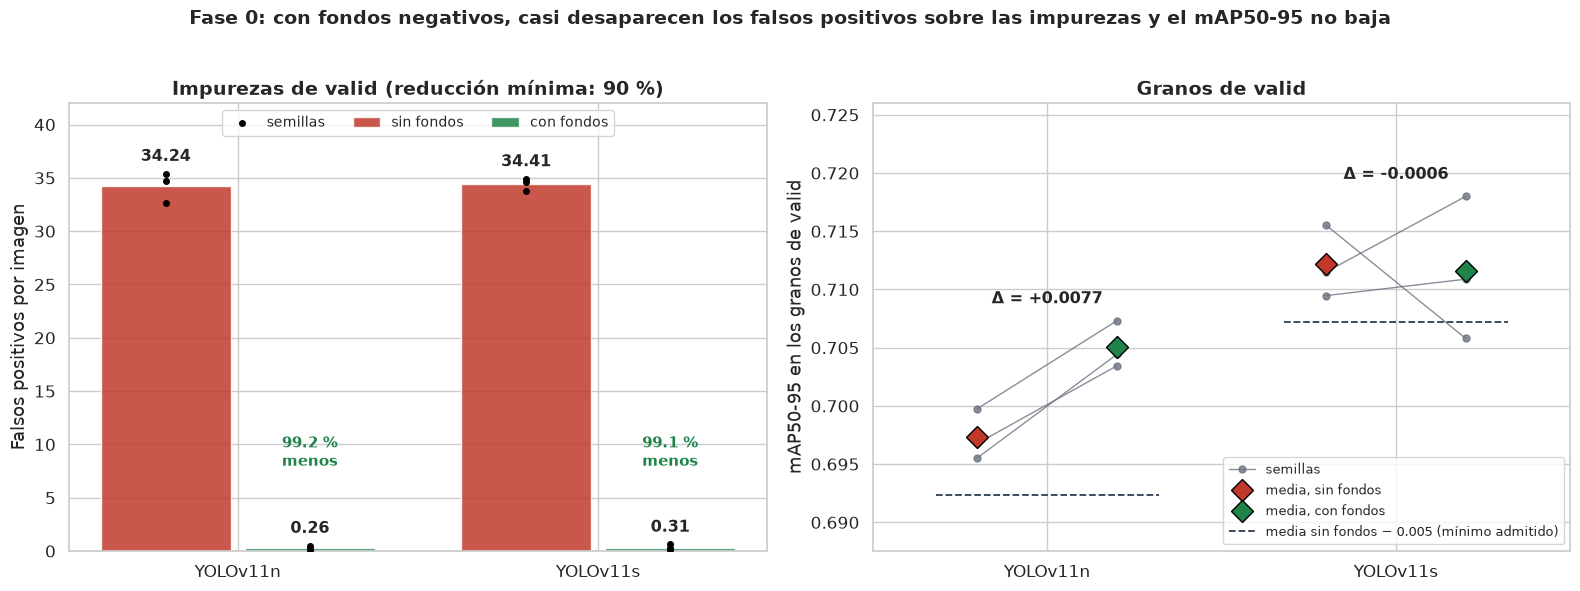

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
ax = axes[0]
for i, modelo in enumerate(E.MODELOS):
    for j, fondos in enumerate((False, True)):
        d = f0[(f0.modelo == modelo) & (f0.fondos == fondos)].fp_impurezas
        x = i + (j - 0.5) * 0.4
        ax.bar(x, d.mean(), 0.36, color=COLOR[fondos], alpha=0.85, label=VERSION[fondos] if i == 0 else None)
        ax.scatter([x] * len(d), d, color='black', s=16, zorder=3, label='semillas' if i == 0 and fondos else None)
        ax.text(x, d.max() + 1.2, f'{d.mean():.2f}', ha='center', fontsize=11.5, fontweight='bold')
    ax.text(i + 0.2, 8, f"{dec[modelo]['reduccion_fp'] * 100:.1f} %\nmenos", ha='center', fontsize=11, color=E.OK, fontweight='bold')
ax.set_xticks(range(len(E.MODELOS))); ax.set_xticklabels([ETIQUETA[m] for m in E.MODELOS]); ax.set_ylim(0, 42)
ax.set_ylabel('Falsos positivos por imagen'); ax.legend(loc='upper center', ncol=3, fontsize=10)
ax.set_title(f'Impurezas de valid (reducción mínima: {E.REDUCCION_FP_MIN * 100:.0f} %)')
ax = axes[1]
for i, modelo in enumerate(E.MODELOS):
    sin = f0[(f0.modelo == modelo) & ~f0.fondos].set_index('semilla').mAP50_95
    con = f0[(f0.modelo == modelo) & f0.fondos].set_index('semilla').mAP50_95
    xs = (i - 0.2, i + 0.2)
    for s in E.SEMILLAS_SELECCION:
        ax.plot(xs, (sin[s], con[s]), color=E.GRIS, lw=1, alpha=0.8, marker='o', ms=5, label='semillas' if i == 0 and s == E.SEMILLAS_SELECCION[0] else None)
    for x, v, fondos in zip(xs, (sin, con), (False, True)):
        ax.plot(x, v.mean(), 'D', ms=11, color=COLOR[fondos], mec='black', zorder=4, label=f'media, {VERSION[fondos]}' if i == 0 else None)
    ax.hlines(sin.mean() - E.GANANCIA_MIN, i - 0.32, i + 0.32, color=E.NEUTRO, ls='--', lw=1.3,
              label=f'media sin fondos − {E.GANANCIA_MIN} (mínimo admitido)' if i == 0 else None)
    ax.text(i, max(sin.max(), con.max()) + 0.0015, f'Δ = {con.mean() - sin.mean():+.4f}', ha='center', fontsize=11.5, fontweight='bold')
ax.set_xticks(range(len(E.MODELOS))); ax.set_xticklabels([ETIQUETA[m] for m in E.MODELOS]); ax.set_xlim(-0.5, 1.5)
lo, hi = f0.mAP50_95.min(), f0.mAP50_95.max()
ax.set_ylim(lo - 0.008, hi + 0.008); ax.set_ylabel('mAP50-95 en los granos de valid'); ax.legend(fontsize=9.5, loc='lower right')
ax.set_title('Granos de valid')
fig.suptitle('Fase 0: con fondos negativos, casi desaparecen los falsos positivos sobre las impurezas y el mAP50-95 no baja',
             fontsize=14, fontweight='bold', y=1.02)
C.guardar(SALIDA, 'fondos_decision.png')

### 2.2. Falsos positivos por tipo de fondo

Se repite en local la inferencia de cada corrida sobre los fondos de medición, con el mismo umbral, para separar los falsos positivos por tipo de fondo y medir qué fracción de las impurezas anotadas se detecta como grano (una detección la cubre con IoU ≥ 0.5). La misma pasada evalúa los granos de `valid` para la sección 2.3.

In [6]:
info = E.fondos_info()
MEDICION = [E.FONDOS / 'images' / f'{n}.jpg' for n in info['particiones']['valid']['medicion']]
VALID = sorted((E.FINAL / 'valid' / 'images').glob('*.jpg'))

def cajas_impurezas(p):
    H, W = cv2.imread(str(p)).shape[:2]
    c, _ = C.leer_yolo(E.FONDOS / 'impurezas' / f'{p.stem}.txt')
    c = np.array(c, float).reshape(-1, 4)
    return np.stack([(c[:, 0] - c[:, 2] / 2) * W, (c[:, 1] - c[:, 3] / 2) * H, (c[:, 0] + c[:, 2] / 2) * W, (c[:, 1] + c[:, 3] / 2) * H], 1)

ANOT = {p.stem: cajas_impurezas(p) for p in MEDICION}
fp, granos, pred_medicion = [], [], {}
for _, f in f0.iterrows():
    pesos = RUNS / f['id'] / 'weights' / 'best.pt'
    pred_medicion[f['id']] = E.predecir(pesos, MEDICION, E.CONF_APLICACION)
    for stem, (pb, pc, pf) in pred_medicion[f['id']].items():
        pares = E.emparejar(ANOT[stem], pb)[0] if len(ANOT[stem]) else {}
        fp.append({'id': f['id'], 'modelo': ETIQUETA[f['modelo']], 'versión': VERSION[f['fondos']], 'semilla': f['semilla'], 'imagen': stem,
                   'tipo': info['imagenes'][stem]['tipo'], 'detecciones': len(pb), 'Defect': int((pc == 1).sum()),
                   'objetos': len(ANOT[stem]), 'cubiertos': len(pares)})
    g, _ = E.diagnosticar(E.predecir(pesos, VALID, E.CONF_APLICACION), 'valid')
    granos.append(g.drop(columns='caja').assign(modelo=ETIQUETA[f['modelo']], versión=VERSION[f['fondos']], semilla=f['semilla']))
fp, granos = pd.DataFrame(fp), pd.concat(granos, ignore_index=True)
local = fp[fp.tipo != 'hoja'].groupby('id').detecciones.mean()
# La inferencia local usa otra GPU y otra versión de PyTorch: puede diferir en alguna detección suelta
dif = (local - f0.set_index('id').fp_impurezas).abs().max()
n_imp = fp[fp.tipo != 'hoja'].imagen.nunique()
print(f'Diferencia máxima con los falsos positivos registrados en Colab: {dif:.3f} detecciones por imagen '
      f'(una diferencia de {round(dif * n_imp)} en el total de las {n_imp} imágenes de impurezas de una corrida)')

t = fp.groupby(['modelo', 'tipo', 'versión']).agg(imágenes=('imagen', 'nunique'), det=('detecciones', 'mean'), total=('detecciones', 'sum'),
                                                  defect=('Defect', 'sum'), obj=('objetos', 'sum'), cub=('cubiertos', 'sum'))
t['detecciones por imagen'] = t['det']
t['impurezas detectadas como grano'] = t['cub'] / t['obj'].where(t['obj'] > 0)
t['detecciones Defect'] = t['defect'] / t['total'].where(t['total'] > 0)
COLUMNAS = ['imágenes', 'detecciones por imagen', 'impurezas detectadas como grano', 'detecciones Defect']
display(t[COLUMNAS].unstack('versión').reindex(columns=pd.MultiIndex.from_product([COLUMNAS, ['sin fondos', 'con fondos']])).round(3))
resto = fp[(fp['versión'] == 'con fondos') & (fp.detecciones > 0)]
print(f"Con fondos quedan {resto.detecciones.sum()} detecciones en {len(f0) // 2} corridas, sobre {resto.imagen.nunique()} imágenes: "
      f"{ {k: int(v) for k, v in resto.groupby('tipo').detecciones.sum().items()} }")

Diferencia máxima con los falsos positivos registrados en Colab: 0.056 detecciones por imagen (una diferencia de 1 en el total de las 18 imágenes de impurezas de una corrida)


imágenes            detecciones por imagen             \
                   sin fondos con fondos             sin fondos con fondos   
modelo   tipo                                                                
YOLOv11n Inorganic          4          4                 31.000      0.000   
         Organic           14         14                 35.167      0.333   
         hoja               3          3                  0.111      0.000   
YOLOv11s Inorganic          4          4                 30.583      0.000   
         Organic           14         14                 35.476      0.405   
         hoja               3          3                  0.000      0.111   

                   impurezas detectadas como grano             \
                                        sin fondos con fondos   
modelo   tipo                                                   
YOLOv11n Inorganic                           0.989      0.000   
         Organic                             0.996      0.011   
         hoja                                  NaN        NaN   
YOLOv11s Inorganic                           0.989      0.000   
         Organic                             0.995      0.012   
         hoja                                  NaN        NaN   

                   detecciones Defect             
                           sin fondos con fondos  
modelo   tipo                                     
YOLOv11n Inorganic              0.957        NaN  
         Organic                1.000      0.500  
         hoja                   1.000        NaN  
YOLOv11s Inorganic              0.924        NaN  
         Organic                1.000      0.706  
         hoja                     NaN      1.000

Con fondos quedan 32 detecciones en 6 corridas, sobre 6 imágenes: {'Organic': 31, 'hoja': 1}


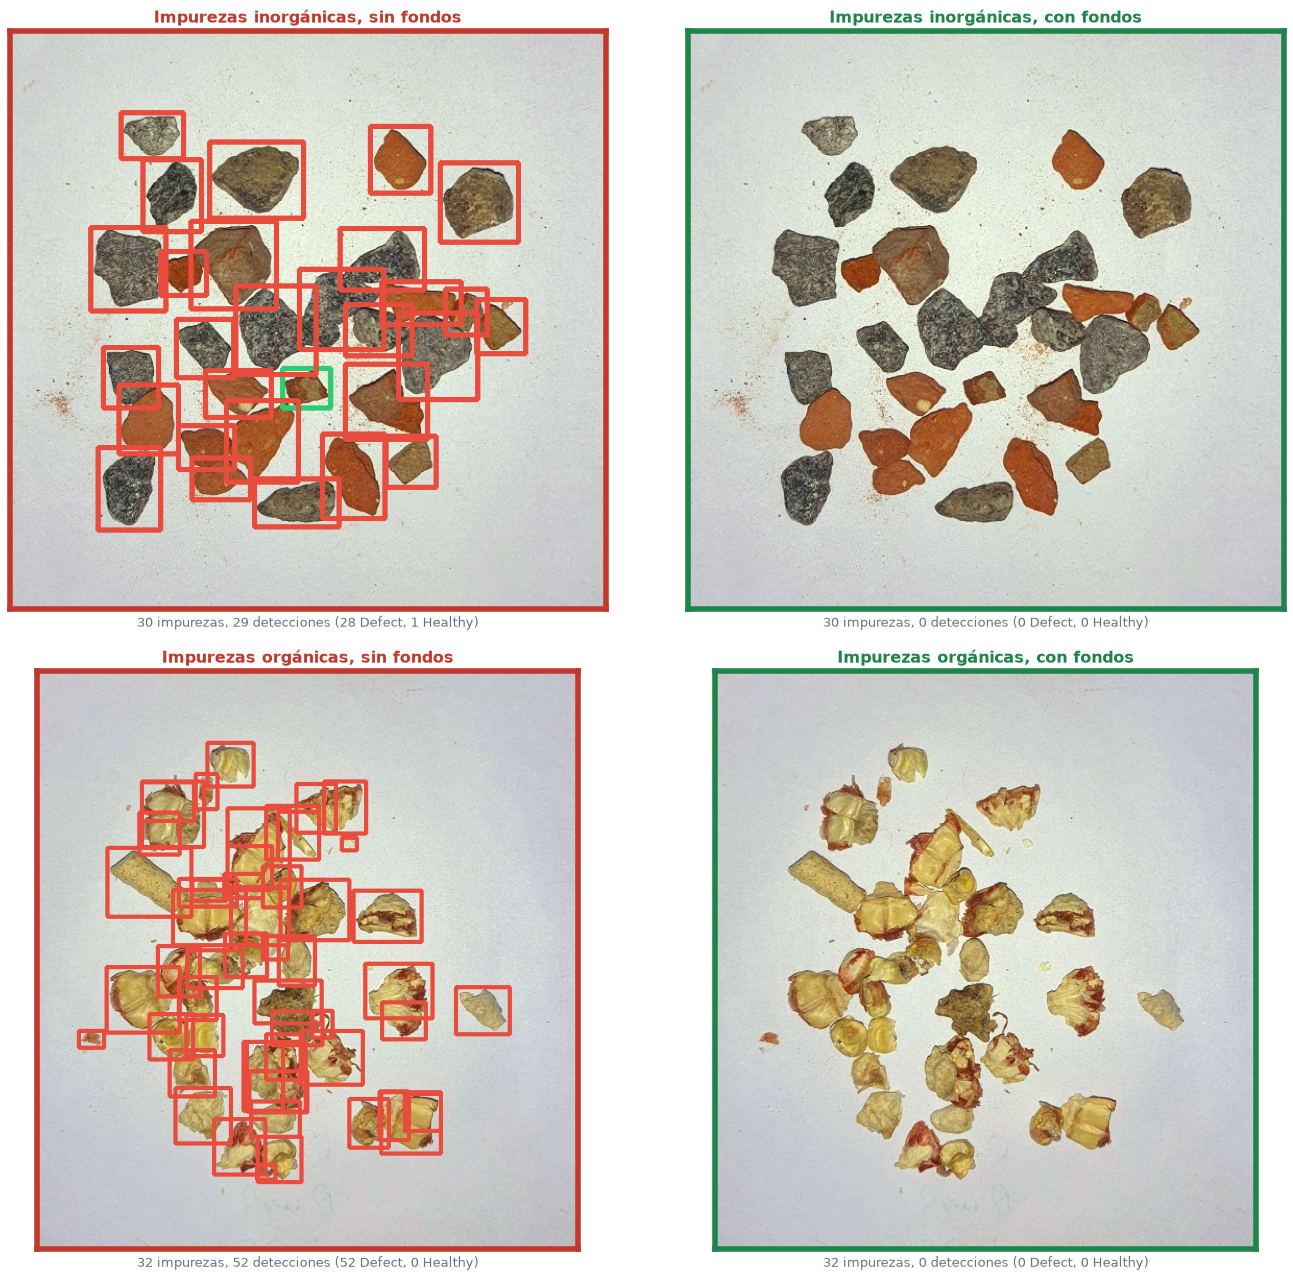

In [7]:
# Una impureza inorgánica y una orgánica de valid, sin y con fondos (YOLOv11s, primera semilla), recortadas a la zona
# de las impurezas
ejemplos = [next(p for p in MEDICION if info['imagenes'][p.stem]['tipo'] == t) for t in ('Inorganic', 'Organic')]
TIPO = {'Inorganic': 'inorgánicas', 'Organic': 'orgánicas'}
fig, axes = plt.subplots(2, 2, figsize=(14, 13))
for fila, p in zip(axes, ejemplos):
    img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
    x1, y1 = (ANOT[p.stem][:, :2].min(0) - 80).clip(0).astype(int)
    x2, y2 = (ANOT[p.stem][:, 2:].max(0) + 80).astype(int)
    for ax, fondos in zip(fila, (False, True)):
        rid = E.id_corrida('yolo11s', dict(E.REFERENCIA, fondos=fondos), E.SEMILLAS_SELECCION[0], 'valid')
        pb, pc, _ = pred_medicion[rid][p.stem]
        vista = E.dibujar(E.dibujar(img, pb[pc == 0], E.CAJA_OK, 4), pb[pc == 1], E.CAJA_MAL, 4)[y1:y2, x1:x2]
        E.mostrar(ax, vista, f"Impurezas {TIPO[info['imagenes'][p.stem]['tipo']]}, {VERSION[fondos]}",
                  f'{len(ANOT[p.stem])} impurezas, {len(pb)} detecciones ({(pc == 1).sum()} Defect, {(pc == 0).sum()} Healthy)',
                  estado='ok' if fondos else 'mal')
C.guardar(SALIDA, 'fondos_ejemplos.png')

### 2.3. Efecto en los granos de `valid`

Métricas de detección y de conteo de los granos, con y sin fondos: media de las 3 semillas, diferencia media (con − sin, emparejada por semilla) y en cuántas semillas mejora. El precision y el recall son los de Ultralytics, al umbral de máximo F1; el MAE de conteo y el acierto por subtipo, al umbral de 0.25.

In [8]:
METRICAS = ['mAP50_95', 'mAP50', 'mAP75', 'precision', 'recall', 'AP50_95_Healthy', 'AP50_95_Defect', 'f1_max', 'mae_conteo']
filas = []
for modelo in E.MODELOS:
    a = f0[(f0.modelo == modelo) & ~f0.fondos].set_index('semilla')[METRICAS]
    b = f0[(f0.modelo == modelo) & f0.fondos].set_index('semilla')[METRICAS]
    d = b - a
    mejora = d.mul([-1 if m == 'mae_conteo' else 1 for m in METRICAS])   # en el MAE, mejorar es bajar
    filas.append(pd.DataFrame({'sin fondos': a.mean(), 'con fondos': b.mean(), 'diferencia': d.mean(),
                               'semillas en que mejora': (mejora > 0).sum()}).assign(modelo=ETIQUETA[modelo]))
display(pd.concat(filas).set_index('modelo', append=True).swaplevel().round(4))

# Acierto por subtipo (clase binaria correcta, IoU >= 0.5) de cada corrida
SUB = [c for c in f0.columns if c.startswith('acierto_')]
sub = f0.assign(modelo=f0.modelo.map(ETIQUETA), versión=f0.fondos.map(VERSION)).set_index(['modelo', 'versión', 'semilla'])[SUB]
display(sub.rename(columns=lambda c: c.removeprefix('acierto_')).sort_index(level=[0, 1], ascending=[True, False]).round(3))

# Estado de cada grano: acierto, clase cambiada (Healthy <-> Defect) o no detectado; fracción de los granos de las 3 semillas
est = granos.groupby(['modelo', 'versión']).estado.value_counts(normalize=True).unstack()[['acierto', 'clase cambiada', 'no detectado']]
display(est.sort_index(ascending=[True, False]).round(4).rename_axis(columns='fracción de los granos'))
inm = granos[granos.subtipo == 'Immature'].groupby(['modelo', 'versión', 'semilla']).estado.value_counts().unstack(fill_value=0)
display(inm.sort_index(ascending=[True, False, True]).rename_axis(columns='granos Immature'))

sin fondos  con fondos  diferencia  \
modelo                                                         
YOLOv11n mAP50_95             0.6974      0.7051      0.0077   
         mAP50                0.9469      0.9574      0.0105   
         mAP75                0.8397      0.8457      0.0060   
         precision            0.8142      0.8599      0.0457   
         recall               0.9169      0.8975     -0.0194   
         AP50_95_Healthy      0.6931      0.6956      0.0025   
         AP50_95_Defect       0.7016      0.7146      0.0129   
         f1_max               0.8582      0.8765      0.0183   
         mae_conteo           0.7333      0.6145     -0.1188   
YOLOv11s mAP50_95             0.7122      0.7116     -0.0006   
         mAP50                0.9496      0.9552      0.0056   
         mAP75                0.8490      0.8391     -0.0100   
         precision            0.8364      0.8265     -0.0099   
         recall               0.8988      0.9250      0.0262   
         AP50_95_Healthy      0.6981      0.6969     -0.0012   
         AP50_95_Defect       0.7262      0.7262      0.0000   
         f1_max               0.8653      0.8699      0.0046   
         mae_conteo           0.6174      0.6000     -0.0174   

                          semillas en que mejora  
modelo                                            
YOLOv11n mAP50_95                              3  
         mAP50                                 3  
         mAP75                                 3  
         precision                             3  
         recall                                1  
         AP50_95_Healthy                       1  
         AP50_95_Defect                        2  
         f1_max                                3  
         mae_conteo                            3  
YOLOv11s mAP50_95                              2  
         mAP50                                 2  
         mAP75                                 1  
         precision                             1  
         recall                                3  
         AP50_95_Healthy                       1  
         AP50_95_Defect                        2  
         f1_max                                2  
         mae_conteo                            1

Broken  Damage  Fungus  Healthy  Immature  \
modelo   versión    semilla                                              
YOLOv11n sin fondos 13        0.960   0.986   0.998    0.708     0.691   
                    29        0.886   0.883   0.984    0.802     0.739   
                    51        0.869   0.864   0.989    0.795     0.747   
         con fondos 13        0.795   0.715   0.974    0.878     0.806   
                    29        0.869   0.860   0.986    0.793     0.869   
                    51        0.807   0.776   0.980    0.840     0.863   
YOLOv11s sin fondos 13        0.801   0.757   0.951    0.844     0.871   
                    29        0.835   0.869   0.956    0.856     0.874   
                    51        0.756   0.729   0.946    0.931     0.856   
         con fondos 13        0.830   0.836   0.967    0.879     0.867   
                    29        0.903   0.963   0.998    0.799     0.362   
                    51        0.864   0.799   0.945    0.905     0.823   

                             Shriveled  Weeveled  
modelo   versión    semilla                       
YOLOv11n sin fondos 13           0.952     0.978  
                    29           0.934     0.939  
                    51           0.941     0.860  
         con fondos 13           0.931     0.832  
                    29           0.936     0.941  
                    51           0.934     0.849  
YOLOv11s sin fondos 13           0.877     0.690  
                    29           0.928     0.679  
                    51           0.931     0.570  
         con fondos 13           0.941     0.707  
                    29           0.958     0.969  
                    51           0.918     0.659

fracción de los granos  acierto  clase cambiada  no detectado
modelo   versión                                             
YOLOv11n sin fondos      0.8586          0.1394        0.0020
         con fondos      0.8806          0.1168        0.0026
YOLOv11s sin fondos      0.8680          0.1298        0.0022
         con fondos      0.8648          0.1326        0.0025

granos Immature              acierto  clase cambiada  no detectado
modelo   versión    semilla                                       
YOLOv11n sin fondos 13           375             166             0
                    29           402             139             0
                    51           404             137             0
         con fondos 13           436             103             2
                    29           470              70             1
                    51           467              74             0
YOLOv11s sin fondos 13           471              69             1
                    29           473              68             0
                    51           463              77             1
         con fondos 13           469              72             0
                    29           196             341             4
                    51           445              96             0

### 2.4. Convergencia y costo

mAP50-95 en los granos de `valid` por época (el `valid` del entrenamiento solo tiene granos, en las dos versiones); el punto marca la época de `best.pt`.

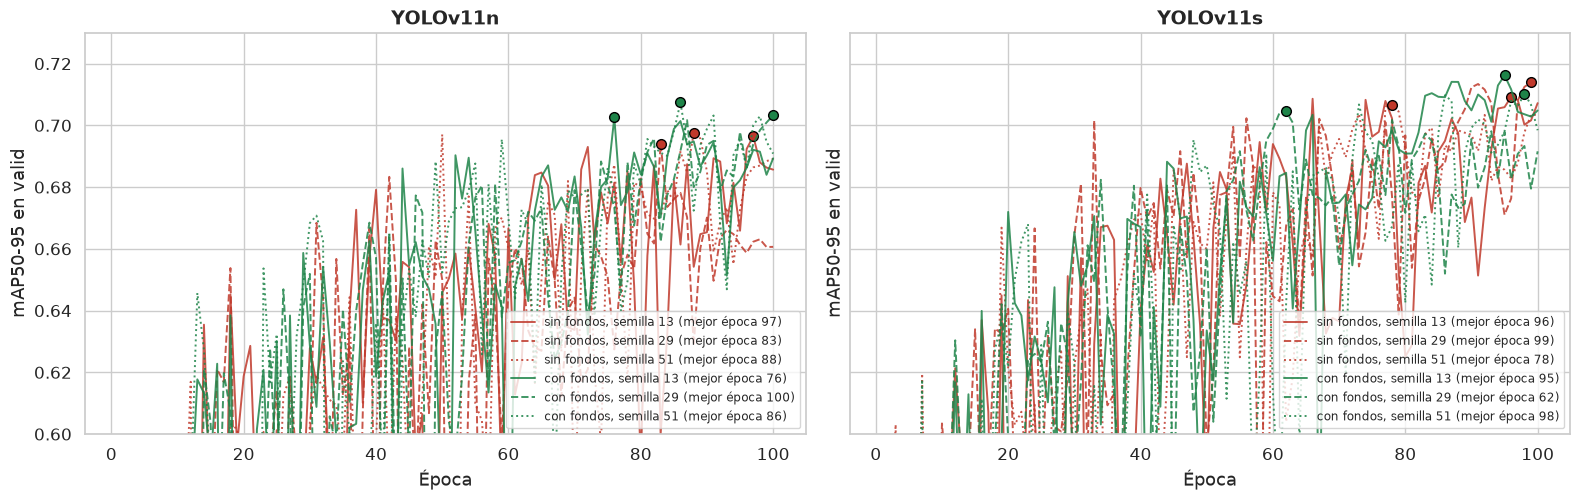

mejor época (mín.)  mejor época (máx.)  \
modelo   versión                                              
YOLOv11n con fondos                76.0               100.0   
         sin fondos                83.0                97.0   
YOLOv11s con fondos                62.0                98.0   
         sin fondos                78.0                99.0   

                     minutos por corrida  VRAM máx. (GB)  
modelo   versión                                          
YOLOv11n con fondos                  8.9            18.0  
         sin fondos                  8.3            17.1  
YOLOv11s con fondos                  9.3            24.2  
         sin fondos                  8.9            24.2

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), sharey=True)
estilos = dict(zip(E.SEMILLAS_SELECCION, ('-', '--', ':')))
for ax, modelo in zip(axes, E.MODELOS):
    for _, f in f0[f0.modelo == modelo].sort_values(['fondos', 'semilla']).iterrows():
        curva = pd.read_csv(RUNS / f['id'] / 'results.csv'); curva.columns = [c.strip() for c in curva.columns]
        ax.plot(curva['epoch'], curva['metrics/mAP50-95(B)'], lw=1.4, ls=estilos[f['semilla']], color=COLOR[f['fondos']], alpha=0.85,
                label=f"{VERSION[f['fondos']]}, semilla {f['semilla']} (mejor época {int(f['mejor_epoca'])})")
        ax.plot(f['mejor_epoca'], curva['metrics/mAP50-95(B)'].max(), 'o', ms=7, color=COLOR[f['fondos']], mec='black')
    ax.set_ylim(0.6, 0.73); ax.set_title(ETIQUETA[modelo]); ax.set_xlabel('Época'); ax.set_ylabel('mAP50-95 en valid'); ax.legend(fontsize=8.5, loc='lower right')
C.guardar(SALIDA, 'fondos_convergencia.png')
f0.assign(modelo=f0.modelo.map(ETIQUETA), versión=f0.fondos.map(VERSION)).groupby(['modelo', 'versión']).agg(
    **{'mejor época (mín.)': ('mejor_epoca', 'min'), 'mejor época (máx.)': ('mejor_epoca', 'max'),
       'minutos por corrida': ('minutos', 'mean'), 'VRAM máx. (GB)': ('vram_gb', 'max')}).round(1)

### 2.5. Resultado de la fase 0

La decisión se guarda en `resultados/decision_fondos.json`. El cribado usa el dataset elegido y toma como referencia las 3 corridas de esa versión, sin repetirlas.

## 3. Cribado

Por modelo, en `train` / `valid` y con los fondos adoptados en la fase 0. Los factores se prueban en orden, cada uno sobre la base vigente:
1. **optimizador:** SGD (referencia), MuSGD, Adam y AdamW, cada uno con su tasa estándar;
2. **tasa de aprendizaje:** ×0.5 y ×2 de la tasa estándar del optimizador vigente;
3. **aumento en línea:** A (referencia), B y C.

Cada configuración se entrena con las semillas 13, 29 y 51 y se compara por su mAP50-95 medio en los granos de `valid`. Una alternativa pasa a ser la base si supera a la base vigente en al menos **+0.005**; si no, se mantiene la base. La referencia son las corridas con fondos de la fase 0.

### 3.1. Decisión por paso

In [10]:
fondos = dec['adoptar']
cribados = {}
for modelo in E.MODELOS:
    t, ganadora = E.cribado(modelo, REGISTRO, fondos)
    assert ganadora is not None, f'{modelo}: faltan corridas del cribado'
    base_paso, filas = t['mAP50_95'].iloc[0], []
    for paso, g in t.groupby('paso', sort=False):
        filas.append(g.assign(**{'base del paso': base_paso, 'diferencia con la base': g['mAP50_95'] - base_paso}))
        if g['elegida'].any() and paso != 'Referencia':
            base_paso = g.loc[g['elegida'], 'mAP50_95'].iloc[0]
    t = pd.concat(filas)
    cribados[modelo] = (t, ganadora)
    ref = dict(E.REFERENCIA, fondos=fondos)
    print(f"{ETIQUETA[modelo]}: ganadora del cribado = {ganadora['optimizer']}, lr0 {ganadora['lr0']:g}, aumento {ganadora['aumento']}"
          + (' (la referencia)' if ganadora == ref else ' -> pasa a la confirmación'))
    display(t.drop(columns=['batch', 'fondos', 'base del paso']).set_index('paso').round(4))
_ = (RAIZ / 'resultados' / 'decision_cribado.json').write_text(json.dumps(
    {'regla': {'ganancia_min': E.GANANCIA_MIN, 'semillas': list(E.SEMILLAS_SELECCION)},
     **{m: {'ganadora': g, 'necesita_confirmacion': g != dict(E.REFERENCIA, fondos=fondos),
            'mAP50_95': round(float(t.loc[t['elegida'], 'mAP50_95'].iloc[-1]), 4),
            'mAP50_95_referencia': round(float(t['mAP50_95'].iloc[0]), 4)} for m, (t, g) in cribados.items()}},
    indent=1, ensure_ascii=False))

YOLOv11n: ganadora del cribado = Adam, lr0 0.001, aumento A -> pasa a la confirmación


,optimizer,lr0,aumento,mAP50_95,sd,semilla 13,semilla 29,semilla 51,elegida,diferencia con la base
paso,,,,,,,,,,
Referencia,SGD,0.0100,A,0.7051,0.0020,0.7034,0.7044,0.7073,True,0.0000
Optimizador,MuSGD,0.0100,A,0.7078,0.0053,0.7076,0.7133,0.7027,False,0.0028
Optimizador,Adam,0.0010,A,0.7103,0.0039,0.7148,0.7078,0.7084,True,0.0053
Optimizador,AdamW,0.0010,A,0.7049,0.0044,0.7002,0.7089,0.7056,False,-0.0002
Tasa de aprendizaje,Adam,0.0005,A,0.7023,0.0049,0.7003,0.6987,0.7080,False,-0.0080
Tasa de aprendizaje,Adam,0.0020,A,0.7064,0.0029,0.7092,0.7067,0.7034,False,-0.0039
Aumento,Adam,0.0010,B,0.7020,0.0007,0.7012,0.7024,0.7024,False,-0.0083
Aumento,Adam,0.0010,C,0.6994,0.0085,0.6900,0.7017,0.7066,False,-0.0109


YOLOv11s: ganadora del cribado = SGD, lr0 0.01, aumento C -> pasa a la confirmación


,optimizer,lr0,aumento,mAP50_95,sd,semilla 13,semilla 29,semilla 51,elegida,diferencia con la base
paso,,,,,,,,,,
Referencia,SGD,0.010,A,0.7116,0.0061,0.7180,0.7058,0.7109,True,0.0000
Optimizador,MuSGD,0.010,A,0.7123,0.0087,0.7149,0.7025,0.7194,False,0.0007
Optimizador,Adam,0.001,A,0.7077,0.0026,0.7083,0.7100,0.7048,False,-0.0038
Optimizador,AdamW,0.001,A,0.7132,0.0037,0.7111,0.7109,0.7175,False,0.0016
Tasa de aprendizaje,SGD,0.005,A,0.7106,0.0122,0.7228,0.6984,0.7105,False,-0.0010
Tasa de aprendizaje,SGD,0.020,A,0.7070,0.0070,0.7149,0.7044,0.7017,False,-0.0046
Aumento,SGD,0.010,B,0.7077,0.0044,0.7108,0.7026,0.7097,False,-0.0039
Aumento,SGD,0.010,C,0.7166,0.0093,0.7200,0.7238,0.7061,True,0.0051


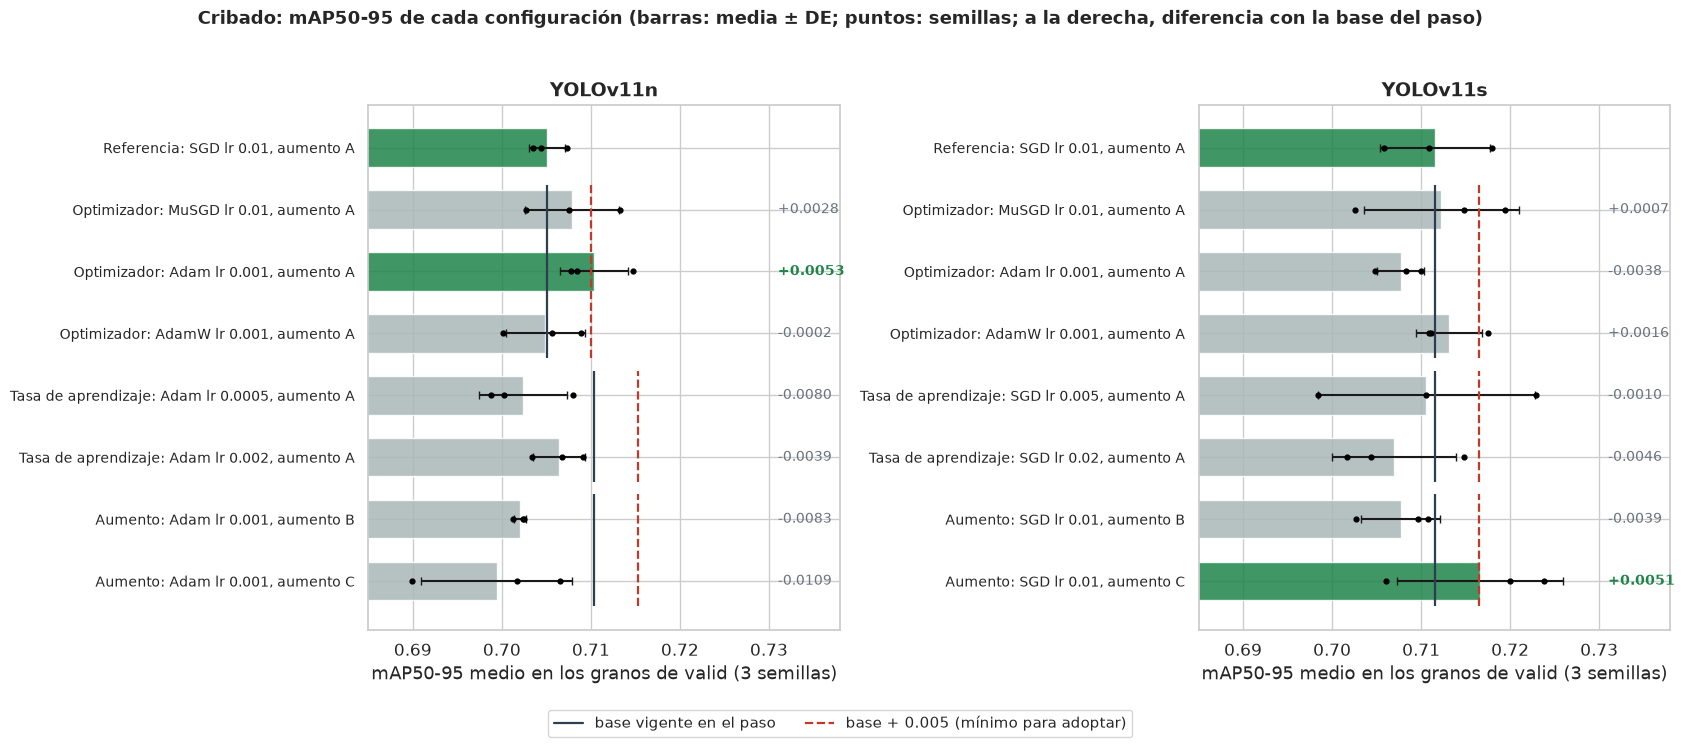

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.8), sharex=True)
for ax, (modelo, (t, _)) in zip(axes, cribados.items()):
    t = t.reset_index(drop=True)
    y = np.arange(len(t))[::-1]
    ax.barh(y, t['mAP50_95'], xerr=t['sd'], capsize=3, height=0.62, alpha=0.85,
            color=[E.OK if e else '#AAB7B8' for e in t['elegida']])
    for yi, (_, f) in zip(y, t.iterrows()):
        ax.scatter([f[f'semilla {s}'] for s in E.SEMILLAS_SELECCION], [yi] * 3, color='black', s=12, zorder=3)
        if f['paso'] != 'Referencia':
            ax.text(0.731, yi, f"{f['diferencia con la base']:+.4f}", va='center', fontsize=10,
                    color=E.OK if f['elegida'] else E.GRIS, fontweight='bold' if f['elegida'] else None)
    for paso, g in t.groupby('paso', sort=False):   # base vigente y umbral de cada paso
        if paso == 'Referencia':
            continue
        ys = y[g.index]
        ax.vlines(g['base del paso'].iloc[0], ys.min() - 0.4, ys.max() + 0.4, color=E.NEUTRO, lw=1.6)
        ax.vlines(g['base del paso'].iloc[0] + E.GANANCIA_MIN, ys.min() - 0.4, ys.max() + 0.4, color=E.MAL, ls='--', lw=1.6)
    etiquetas = [f"{p}: {o} lr {lr:g}, aumento {a}" for p, o, lr, a in t[['paso', 'optimizer', 'lr0', 'aumento']].itertuples(index=False)]
    ax.set_yticks(y); ax.set_yticklabels(etiquetas, fontsize=10); ax.set_title(ETIQUETA[modelo])
    ax.set_xlim(0.685, 0.738); ax.set_xlabel('mAP50-95 medio en los granos de valid (3 semillas)')
axes[0].plot([], [], color=E.NEUTRO, lw=1.6, label='base vigente en el paso')
axes[0].plot([], [], color=E.MAL, ls='--', lw=1.6, label='base + 0.005 (mínimo para adoptar)')
fig.legend(loc='lower center', ncol=2, fontsize=10.5, bbox_to_anchor=(0.5, -0.06))
fig.suptitle('Cribado: mAP50-95 de cada configuración (barras: media ± DE; puntos: semillas; a la derecha, diferencia con la base del paso)',
             fontsize=13, fontweight='bold', y=1.02)
C.guardar(SALIDA, 'cribado.png')

### 3.2. Métricas secundarias y costo

Media de las 3 semillas de cada configuración: detección, conteo (umbral de 0.25), falsos positivos sobre los fondos de medición de `valid` y costo. No intervienen en la decisión.

In [12]:
cr = pd.concat([f0[f0.fondos == fondos], reg[reg['fase'] == 'cribado']])
cr = cr.sort_values('modelo', kind='stable').assign(modelo=cr.modelo.map(ETIQUETA), configuración=cr.optimizer + ', lr0 ' + cr.lr0.map('{:g}'.format) + ', aumento ' + cr.aumento)
display(cr.groupby(['modelo', 'configuración'], sort=False)[
    ['mAP50_95', 'mAP50', 'mAP75', 'precision', 'recall', 'f1_max', 'mae_conteo', 'fp_impurezas', 'mejor_epoca', 'minutos']]
    .mean().round(3).rename(columns={'fp_impurezas': 'FP por imagen, impurezas', 'mejor_epoca': 'mejor época'}))
print(f"Cribado: {(reg['fase'] == 'cribado').sum()} corridas, {reg.loc[reg['fase'] == 'cribado', 'minutos'].sum() / 60:.1f} h; "
      f"minutos por corrida según el aumento: {cr[cr.fase == 'cribado'].groupby('aumento').minutos.mean().round(1).to_dict()}")

mAP50_95  mAP50  mAP75  precision  \
modelo   configuración                                                    
YOLOv11n SGD, lr0 0.01, aumento A        0.705  0.957  0.846      0.860   
         MuSGD, lr0 0.01, aumento A      0.708  0.946  0.848      0.809   
         Adam, lr0 0.001, aumento A      0.710  0.960  0.858      0.845   
         AdamW, lr0 0.001, aumento A     0.705  0.960  0.848      0.851   
         Adam, lr0 0.0005, aumento A     0.702  0.954  0.844      0.840   
         Adam, lr0 0.002, aumento A      0.706  0.958  0.858      0.839   
         Adam, lr0 0.001, aumento B      0.702  0.952  0.852      0.806   
         Adam, lr0 0.001, aumento C      0.699  0.944  0.839      0.811   
YOLOv11s SGD, lr0 0.01, aumento A        0.712  0.955  0.839      0.826   
         MuSGD, lr0 0.01, aumento A      0.712  0.956  0.846      0.865   
         Adam, lr0 0.001, aumento A      0.708  0.955  0.852      0.871   
         AdamW, lr0 0.001, aumento A     0.713  0.960  0.853      0.877   
         SGD, lr0 0.005, aumento A       0.711  0.953  0.836      0.848   
         SGD, lr0 0.02, aumento A        0.707  0.952  0.840      0.837   
         SGD, lr0 0.01, aumento B        0.708  0.941  0.838      0.798   
         SGD, lr0 0.01, aumento C        0.717  0.956  0.859      0.845   

                                      recall  f1_max  mae_conteo  \
modelo   configuración                                             
YOLOv11n SGD, lr0 0.01, aumento A      0.897   0.876       0.614   
         MuSGD, lr0 0.01, aumento A    0.919   0.853       0.739   
         Adam, lr0 0.001, aumento A    0.923   0.878       0.774   
         AdamW, lr0 0.001, aumento A   0.918   0.881       0.806   
         Adam, lr0 0.0005, aumento A   0.920   0.876       0.699   
         Adam, lr0 0.002, aumento A    0.916   0.872       0.951   
         Adam, lr0 0.001, aumento B    0.931   0.863       0.814   
         Adam, lr0 0.001, aumento C    0.915   0.856       0.994   
YOLOv11s SGD, lr0 0.01, aumento A      0.925   0.870       0.600   
         MuSGD, lr0 0.01, aumento A    0.892   0.876       0.609   
         Adam, lr0 0.001, aumento A    0.907   0.887       0.730   
         AdamW, lr0 0.001, aumento A   0.914   0.894       0.774   
         SGD, lr0 0.005, aumento A     0.906   0.873       0.629   
         SGD, lr0 0.02, aumento A      0.909   0.868       0.681   
         SGD, lr0 0.01, aumento B      0.909   0.849       0.739   
         SGD, lr0 0.01, aumento C      0.911   0.873       0.699   

                                      FP por imagen, impurezas  mejor época  \
modelo   configuración                                                        
YOLOv11n SGD, lr0 0.01, aumento A                        0.259       87.333   
         MuSGD, lr0 0.01, aumento A                      0.519       88.667   
         Adam, lr0 0.001, aumento A                      0.093       79.667   
         AdamW, lr0 0.001, aumento A                     0.963       83.000   
         Adam, lr0 0.0005, aumento A                     0.148       57.333   
         Adam, lr0 0.002, aumento A                      1.352       76.667   
         Adam, lr0 0.001, aumento B                      2.463       80.000   
         Adam, lr0 0.001, aumento C                      6.593       71.667   
YOLOv11s SGD, lr0 0.01, aumento A                        0.315       85.000   
         MuSGD, lr0 0.01, aumento A                      0.093       90.667   
         Adam, lr0 0.001, aumento A                      0.093       92.000   
         AdamW, lr0 0.001, aumento A                     0.407       87.667   
         SGD, lr0 0.005, aumento A                       0.074       65.667   
         SGD, lr0 0.02, aumento A                        2.907       95.667   
         SGD, lr0 0.01, aumento B                        0.593       85.333   
         SGD, lr0 0.01, aumento C                        0.278       86.000   

                                      m

Cribado: 42 corridas, 8.1 h; minutos por corrida según el aumento: {'A': 9.3, 'B': 16.8, 'C': 17.9}


### 3.3. Resultado del cribado

Las ganadoras que no son la referencia pasan a la confirmación en los pliegues 0, 1 y 3 de la validación cruzada (`resultados/decision_cribado.json`). El pliegue 2 se excluye: su partición es idéntica a `train` / `valid` y, con las mismas semillas, repetiría las corridas del cribado con que se eligió la ganadora.

## 4. Confirmación

Cada ganadora del cribado se compara con la referencia (SGD, `lr0 = 0.01`, aumento A, con fondos) en los pliegues 0, 1 y 3 de la validación cruzada del OE1, con las semillas 13, 29 y 51: 9 comparaciones emparejadas por pliegue y semilla. Cada corrida entrena con los otros tres pliegues y los fondos de su partición y se evalúa en los granos de su pliegue. El pliegue 2 se excluye porque su partición es la del cribado.

**Regla:** la candidata se adopta si mejora el mAP50-95 en al menos **+0.005 de media** y la mejora es **significativa** (t pareada, p < 0.05). Si no, se mantiene la referencia.

### 4.1. Decisión

In [13]:
from scipy import stats

confirmaciones, filas = {}, []
for modelo in E.MODELOS:
    _, ganadora = cribados[modelo]
    t, adoptada = E.confirmacion(modelo, ganadora, REGISTRO, fondos)
    assert adoptada is not None, f'{modelo}: faltan corridas de la confirmación'
    confirmaciones[modelo] = (t, ganadora, adoptada)
    d = t['candidata'] - t['referencia']
    ic = stats.ttest_rel(t['candidata'], t['referencia']).confidence_interval()
    filas.append({'modelo': ETIQUETA[modelo], 'candidata': f"{ganadora['optimizer']}, lr0 {ganadora['lr0']:g}, aumento {ganadora['aumento']}",
                  'mAP50-95 referencia': t['referencia'].mean(), 'mAP50-95 candidata': t['candidata'].mean(),
                  'diferencia media': d.mean(), 'IC 95 %': f'[{ic.low:+.4f}, {ic.high:+.4f}]', 'valor p': t.attrs['valor_p'],
                  'a favor de la candidata': f"{t.attrs['a_favor']} de {len(t)}",
                  'cumple +0.005': d.mean() >= E.GANANCIA_MIN, 'cumple p < 0.05': t.attrs['valor_p'] < E.ALFA,
                  'se adopta': adoptada == ganadora})
    print(f"{ETIQUETA[modelo]}: configuración adoptada = {adoptada['optimizer']}, lr0 {adoptada['lr0']:g}, aumento {adoptada['aumento']}, "
          f"fondos {adoptada['fondos']}" + (' (la candidata)' if adoptada == ganadora else ' (la referencia)'))
    display(t.assign(diferencia=d).round(4))
resumen_conf = pd.DataFrame(filas).set_index('modelo')
display(resumen_conf.round(4))
_ = (RAIZ / 'resultados' / 'decision_confirmacion.json').write_text(json.dumps(
    {'regla': {'ganancia_min': E.GANANCIA_MIN, 'alfa': E.ALFA, 'pliegues': list(E.PLIEGUES_CONFIRMACION), 'semillas': list(E.SEMILLAS_SELECCION)},
     **{m: {'candidata': g, 'adoptada': a, 'diferencia': round(t.attrs['diferencia'], 4), 'valor_p': round(t.attrs['valor_p'], 4),
            'a_favor': t.attrs['a_favor'], 'comparaciones': len(t)} for m, (t, g, a) in confirmaciones.items()}},
    indent=1, ensure_ascii=False))

YOLOv11n: configuración adoptada = SGD, lr0 0.01, aumento A, fondos True (la referencia)


referencia  candidata  diferencia
pliegue semilla                                   
0       13           0.7326     0.7326      0.0000
        29           0.7381     0.7394      0.0013
        51           0.7369     0.7289     -0.0080
1       13           0.7657     0.7735      0.0078
        29           0.7676     0.7812      0.0135
        51           0.7748     0.7841      0.0094
3       13           0.7430     0.7225     -0.0205
        29           0.7369     0.7527      0.0158
        51           0.7090     0.7323      0.0233

YOLOv11s: configuración adoptada = SGD, lr0 0.01, aumento A, fondos True (la referencia)


referencia  candidata  diferencia
pliegue semilla                                   
0       13           0.7508     0.7551      0.0043
        29           0.7463     0.7535      0.0072
        51           0.7400     0.7581      0.0180
1       13           0.7738     0.7931      0.0194
        29           0.7802     0.7935      0.0133
        51           0.7853     0.7877      0.0023
3       13           0.7664     0.7623     -0.0041
        29           0.7582     0.7644      0.0062
        51           0.7521     0.7451     -0.0070

,candidata,mAP50-95 referencia,mAP50-95 candidata,diferencia media,IC 95 %,valor p,a favor de la candidata,cumple +0.005,cumple p < 0.05,se adopta
modelo,,,,,,,,,,
YOLOv11n,"Adam, lr0 0.001, aumento A",0.7450,0.7497,0.0047,"[-0.0055, +0.0149]",0.3164,7 de 9,False,False,False
YOLOv11s,"SGD, lr0 0.01, aumento C",0.7615,0.7681,0.0066,"[-0.0004, +0.0136]",0.0604,7 de 9,True,False,False


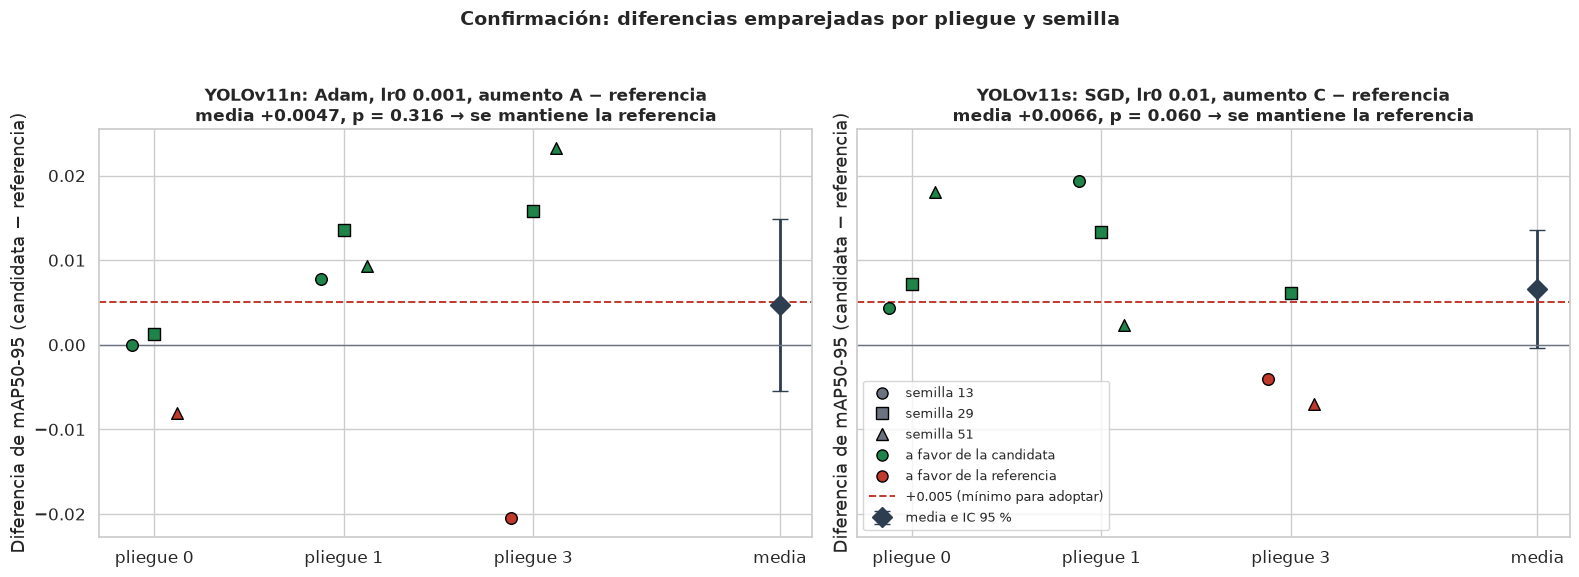

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.6), sharey=True)
marcas = dict(zip(E.SEMILLAS_SELECCION, ('o', 's', '^')))
for ax, (modelo, (t, ganadora, adoptada)) in zip(axes, confirmaciones.items()):
    d = (t['candidata'] - t['referencia']).rename('dif').reset_index()
    pliegues = sorted(d['pliegue'].unique())
    for _, f in d.iterrows():
        x = pliegues.index(f['pliegue']) + (E.SEMILLAS_SELECCION.index(f['semilla']) - 1) * 0.12
        ax.scatter(x, f['dif'], marker=marcas[int(f['semilla'])], s=70, color=E.OK if f['dif'] > 0 else E.MAL, edgecolor='black', zorder=3)
    media = d['dif'].mean()
    ic = stats.ttest_rel(t['candidata'], t['referencia']).confidence_interval()
    xm = len(pliegues) + 0.3
    ax.errorbar(xm, media, yerr=[[media - ic.low], [ic.high - media]], fmt='D', ms=10, color=E.NEUTRO, capsize=6, lw=2,
                label='media e IC 95 %')
    ax.axhline(0, color=E.GRIS, lw=1)
    ax.axhline(E.GANANCIA_MIN, color=E.MAL, ls='--', lw=1.4, label=f'+{E.GANANCIA_MIN} (mínimo para adoptar)')
    ax.set_xticks(list(range(len(pliegues))) + [xm]); ax.set_xticklabels([f'pliegue {p}' for p in pliegues] + ['media'])
    ax.set_title(f"{ETIQUETA[modelo]}: {ganadora['optimizer']}, lr0 {ganadora['lr0']:g}, aumento {ganadora['aumento']} − referencia\n"
                 f"media {media:+.4f}, p = {t.attrs['valor_p']:.3f} → " + ('se adopta' if adoptada == ganadora else 'se mantiene la referencia'),
                 fontsize=12)
    ax.set_ylabel('Diferencia de mAP50-95 (candidata − referencia)')
from matplotlib.lines import Line2D
extra = [Line2D([], [], ls='', marker=m, ms=8, mfc=E.GRIS, mec='black', label=f'semilla {s}') for s, m in marcas.items()]
extra += [Line2D([], [], ls='', marker='o', ms=8, mfc=c, mec='black', label=t) for c, t in ((E.OK, 'a favor de la candidata'), (E.MAL, 'a favor de la referencia'))]
axes[1].legend(handles=extra + axes[1].get_legend_handles_labels()[0], fontsize=9.5, loc='lower left')
fig.suptitle('Confirmación: diferencias emparejadas por pliegue y semilla', fontsize=14, fontweight='bold', y=1.03)
C.guardar(SALIDA, 'confirmacion.png')

### 4.2. Métricas secundarias

Media de las 9 corridas de cada configuración, cada una en la validación de su pliegue: detección, conteo (umbral de 0.25), falsos positivos sobre los fondos de medición de su pliegue y costo. No intervienen en la decisión.

In [15]:
cf = reg[reg['fase'] == 'confirmacion']
cf = cf.assign(modelo=cf.modelo.map(ETIQUETA), configuración=cf.optimizer + ', lr0 ' + cf.lr0.map('{:g}'.format) + ', aumento ' + cf.aumento)
display(cf.groupby(['modelo', 'configuración'])[
    ['mAP50_95', 'mAP50', 'mAP75', 'precision', 'recall', 'f1_max', 'mae_conteo', 'fp_impurezas', 'mejor_epoca', 'minutos']]
    .mean().round(3).rename(columns={'fp_impurezas': 'FP por imagen, impurezas', 'mejor_epoca': 'mejor época'}))
display(cf.pivot_table(index=['modelo', 'configuración'], columns='particion', values='mAP50_95').round(4)
        .rename_axis(columns='mAP50-95 medio por pliegue'))
print(f"Confirmación: {len(cf)} corridas, {cf.minutos.sum() / 60:.1f} h")

mAP50_95  mAP50  mAP75  precision  \
modelo   configuración                                                   
YOLOv11n Adam, lr0 0.001, aumento A     0.750  0.984  0.898      0.959   
         SGD, lr0 0.01, aumento A       0.745  0.981  0.904      0.960   
YOLOv11s SGD, lr0 0.01, aumento A       0.761  0.984  0.917      0.961   
         SGD, lr0 0.01, aumento C       0.768  0.985  0.921      0.950   

                                     recall  f1_max  mae_conteo  \
modelo   configuración                                            
YOLOv11n Adam, lr0 0.001, aumento A   0.965   0.961       0.300   
         SGD, lr0 0.01, aumento A     0.961   0.959       0.314   
YOLOv11s SGD, lr0 0.01, aumento A     0.970   0.965       0.189   
         SGD, lr0 0.01, aumento C     0.972   0.960       0.201   

                                     FP por imagen, impurezas  mejor época  \
modelo   configuración                                                       
YOLOv11n Adam, lr0 0.001, aumento A                     0.099       75.889   
         SGD, lr0 0.01, aumento A                       0.650       73.000   
YOLOv11s SGD, lr0 0.01, aumento A                       0.322       73.667   
         SGD, lr0 0.01, aumento C                       0.373       77.000   

                                     minutos  
modelo   configuración                        
YOLOv11n Adam, lr0 0.001, aumento A    8.800  
         SGD, lr0 0.01, aumento A      8.811  
YOLOv11s SGD, lr0 0.01, aumento A      9.011  
         SGD, lr0 0.01, aumento C     16.722

mAP50-95 medio por pliegue               p0      p1      p3
modelo   configuración                                     
YOLOv11n Adam, lr0 0.001, aumento A  0.7336  0.7796  0.7358
         SGD, lr0 0.01, aumento A    0.7359  0.7694  0.7296
YOLOv11s SGD, lr0 0.01, aumento A    0.7457  0.7797  0.7589
         SGD, lr0 0.01, aumento C    0.7556  0.7914  0.7573

Confirmación: 36 corridas, 6.5 h


### 4.3. Configuración adoptada

Las decisiones de las tres fases, encadenadas a partir del registro (`comun_oe2.configuracion_ajustada`). El entrenamiento final usa esta configuración con las semillas 42, 7 y 28, 200 épocas y `patience = 50`.

In [16]:
adoptadas, _ = E.configuracion_ajustada(REGISTRO)
display(pd.DataFrame({ETIQUETA[m]: {**c, 'imgsz': E.IMGSZ} for m, c in adoptadas.items()}).T
        .rename(columns={'optimizer': 'optimizador', 'batch': 'lote', 'imgsz': 'resolución'}))

,optimizador,lr0,lote,aumento,fondos,resolución
YOLOv11n,SGD,0.01,16,A,True,1280
YOLOv11s,SGD,0.01,16,A,True,1280


## 5. Entrenamiento final

Cada modelo con su configuración adoptada (sección 4.3), con las semillas 42, 7 y 28, distintas de las de selección, en `train` con los fondos y con `valid` como seguimiento: hasta 200 épocas con `patience = 50`. `best.pt` es la época de mayor mAP50-95 en los granos de `valid`.

### 5.1. Métricas en `valid`

In [17]:
fin = reg[reg['fase'] == 'final']
assert len(fin) == len(E.MODELOS) * len(E.SEMILLAS_FINAL), 'Faltan corridas del entrenamiento final'
assert all((fin[fin.modelo == m][['optimizer', 'lr0', 'aumento', 'fondos']].iloc[0].to_dict() ==
            {k: adoptadas[m][k] for k in ('optimizer', 'lr0', 'aumento', 'fondos')}) for m in E.MODELOS), 'Configuración distinta de la adoptada'
METR = ['mAP50_95', 'mAP50', 'mAP75', 'precision', 'recall', 'AP50_95_Healthy', 'AP50_95_Defect', 'f1_max', 'conf_f1']
fin_e = fin.assign(modelo=fin.modelo.map(ETIQUETA))
display(fin_e.set_index(['modelo', 'semilla'])[METR + ['epocas_ejecutadas', 'mejor_epoca', 'minutos', 'vram_gb']].round(4)
        .rename(columns={'epocas_ejecutadas': 'épocas', 'mejor_epoca': 'mejor época'}))
display(fin_e.groupby('modelo')[METR].agg(['mean', 'std']).T.round(4).rename_axis(['métrica', '']))

mAP50_95   mAP50   mAP75  precision  recall  \
modelo   semilla                                                
YOLOv11n 42         0.7067  0.9572  0.8474     0.8743  0.8822   
         7          0.7083  0.9575  0.8472     0.8156  0.9315   
         28         0.7153  0.9535  0.8559     0.8577  0.8994   
YOLOv11s 42         0.7018  0.9500  0.8408     0.7751  0.9371   
         7          0.7171  0.9489  0.8599     0.8076  0.9160   
         28         0.7200  0.9573  0.8521     0.8542  0.9107   

                  AP50_95_Healthy  AP50_95_Defect  f1_max  conf_f1  épocas  \
modelo   semilla                                                             
YOLOv11n 42                0.7025          0.7108  0.8782   0.5245   200.0   
         7                 0.7188          0.6978  0.8626   0.3453   154.0   
         28                0.6978          0.7328  0.8789   0.4775   181.0   
YOLOv11s 42                0.6934          0.7101  0.8425   0.1281   103.0   
         7                 0.7119          0.7223  0.8542   0.2923   180.0   
         28                0.7125          0.7274  0.8810   0.4264   195.0   

                  mejor época  minutos  vram_gb  
modelo   semilla                                 
YOLOv11n 42             164.0     15.6    13.09  
         7              104.0     11.8    17.69  
         28             131.0     13.9    16.59  
YOLOv11s 42              53.0      9.7    24.13  
         7              130.0     16.1    24.18  
         28             145.0     17.4    24.16

modelo                YOLOv11n  YOLOv11s
métrica                                 
mAP50_95        mean    0.7101    0.7129
                std     0.0046    0.0098
mAP50           mean    0.9560    0.9521
                std     0.0022    0.0045
mAP75           mean    0.8502    0.8509
                std     0.0050    0.0096
precision       mean    0.8492    0.8123
                std     0.0303    0.0398
recall          mean    0.9043    0.9213
                std     0.0250    0.0139
AP50_95_Healthy mean    0.7064    0.7059
                std     0.0110    0.0108
AP50_95_Defect  mean    0.7138    0.7199
                std     0.0177    0.0089
f1_max          mean    0.8733    0.8592
                std     0.0092    0.0198
conf_f1         mean    0.4491    0.2823
                std     0.0929    0.1494

### 5.2. Umbral de conteo y métricas de aplicación

El umbral de conteo de cada modelo es la mediana, entre semillas, del umbral de máximo F1 en `valid` (NMS agnóstico a la clase). Queda fijado para el diagnóstico, las fotos propias y la evaluación final. Con ese umbral común se miden en cada corrida el MAE de conteo y el acierto por subtipo en los granos de `valid`, y los falsos positivos sobre los fondos de medición de `valid`.

In [18]:
from ultralytics import YOLO

UMBRAL = fin.groupby('modelo')['conf_f1'].median()
print('Umbral de conteo:', {ETIQUETA[m]: round(float(u), 4) for m, u in UMBRAL.items()})
aplic = []
for _, f in fin.iterrows():
    m = YOLO(str(RUNS / f['id'] / 'weights' / 'best.pt'))
    u = float(UMBRAL[f['modelo']])
    aplic.append({'modelo': ETIQUETA[f['modelo']], 'semilla': f['semilla'],
                  **C.metricas_aplicacion(m, VALID, E.IMGSZ, u), **E.falsos_positivos(m, MEDICION, u)})
    C.liberar_gpu(m)
aplic = pd.DataFrame(aplic).set_index(['modelo', 'semilla']).rename(columns=lambda c: c.removeprefix('acierto_'))
display(aplic.round(3))
display(aplic.groupby('modelo').agg(['mean', 'std']).T.round(3).rename_axis(['métrica', '']))

Umbral de conteo: {'YOLOv11n': 0.4775, 'YOLOv11s': 0.2923}


mae_conteo  Broken  Damage  Fungus  Healthy  Immature  \
modelo   semilla                                                          
YOLOv11n 42            0.348   0.835   0.794   0.965    0.865     0.817   
         7             0.513   0.932   0.930   0.998    0.785     0.433   
         28            0.513   0.756   0.673   0.973    0.881     0.867   
YOLOv11s 42            0.722   0.898   0.921   0.995    0.746     0.416   
         7             0.635   0.830   0.883   0.989    0.816     0.623   
         28            0.739   0.869   0.766   0.965    0.860     0.871   

                  Shriveled  Weeveled  fp_impurezas  fp_hojas  
modelo   semilla                                               
YOLOv11n 42           0.939     0.749         0.444       0.0  
         7            0.966     0.961         0.056       0.0  
         28           0.931     0.827         0.056       0.0  
YOLOv11s 42           0.947     0.989         4.056       0.0  
         7            0.939     0.933         0.222       0.0  
         28           0.930     0.768         0.056       0.0

modelo             YOLOv11n  YOLOv11s
métrica                              
mae_conteo   mean     0.458     0.699
             std      0.095     0.056
Broken       mean     0.841     0.866
             std      0.088     0.034
Damage       mean     0.799     0.857
             std      0.129     0.080
Fungus       mean     0.978     0.983
             std      0.017     0.016
Healthy      mean     0.844     0.808
             std      0.051     0.057
Immature     mean     0.705     0.636
             std      0.238     0.228
Shriveled    mean     0.946     0.939
             std      0.018     0.009
Weeveled     mean     0.845     0.897
             std      0.107     0.115
fp_impurezas mean     0.185     1.444
             std      0.225     2.263
fp_hojas     mean     0.000     0.000
             std      0.000     0.000

### 5.3. Curvas de entrenamiento

mAP50-95 en los granos de `valid` por época. El punto marca `best.pt`, y la cruz, la última época. La línea discontinua marca el inicio de las 10 últimas épocas, sin mosaico (`close_mosaic = 10`).

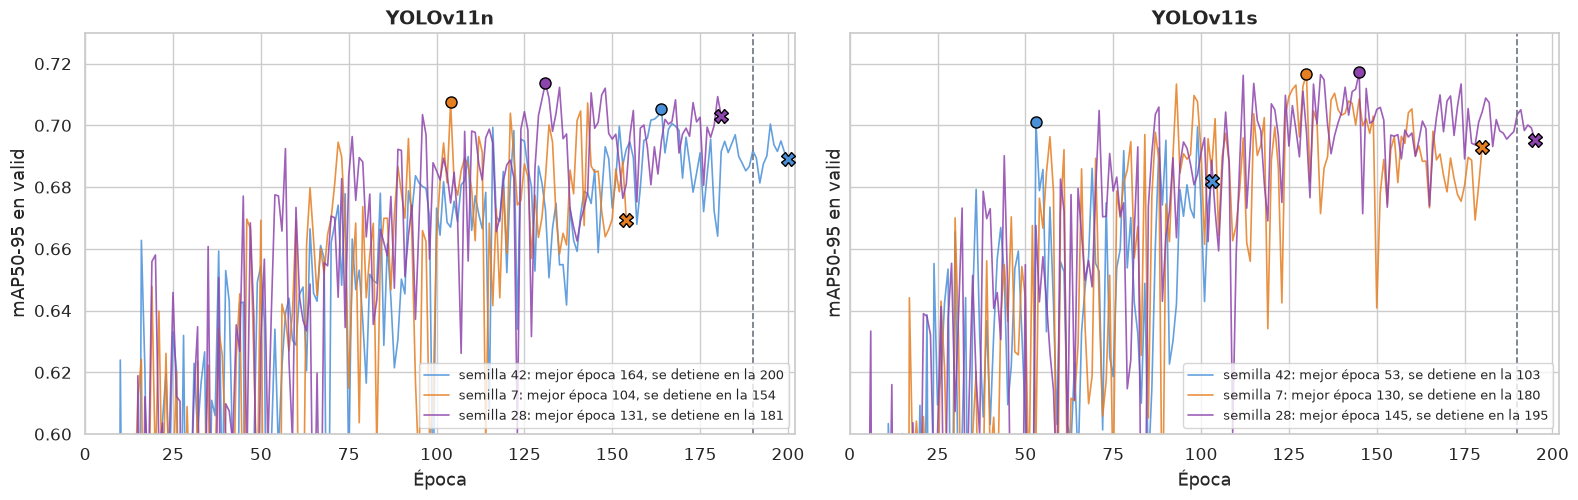

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.2), sharey=True)
colores = dict(zip(E.SEMILLAS_FINAL, ('#4A90D9', '#E67E22', '#8E44AD')))
for ax, modelo in zip(axes, E.MODELOS):
    for _, f in fin[fin.modelo == modelo].iterrows():
        curva = pd.read_csv(RUNS / f['id'] / 'results.csv'); curva.columns = [c.strip() for c in curva.columns]
        v = curva['metrics/mAP50-95(B)']
        ax.plot(curva['epoch'], v, lw=1.2, color=colores[f['semilla']], alpha=0.85,
                label=f"semilla {f['semilla']}: mejor época {int(f['mejor_epoca'])}, se detiene en la {int(f['epocas_ejecutadas'])}")
        ax.plot(f['mejor_epoca'], v.max(), 'o', ms=8, color=colores[f['semilla']], mec='black', zorder=4)
        ax.plot(curva['epoch'].iloc[-1], v.iloc[-1], 'X', ms=10, color=colores[f['semilla']], mec='black', zorder=4)
    ax.axvline(E.EPOCAS_FINAL - 10, color=E.GRIS, ls='--', lw=1.2)
    ax.set_ylim(0.6, 0.73); ax.set_xlim(0, E.EPOCAS_FINAL + 2)
    ax.set_title(ETIQUETA[modelo]); ax.set_xlabel('Época'); ax.set_ylabel('mAP50-95 en valid'); ax.legend(fontsize=9, loc='lower right')
C.guardar(SALIDA, 'final_curvas.png')

### 5.4. Configuración final

Se guarda en `resultados/configuracion_final.json`: por modelo, la configuración, el umbral de conteo y las rutas de los 3 `best.pt` (`comun_oe2.configuracion('final')` las devuelve como rutas absolutas).

In [20]:
config = {m: {**adoptadas[m], 'imgsz': E.IMGSZ, 'epocas': E.EPOCAS_FINAL, 'paciencia': E.PACIENCIA_FINAL,
              'semillas': list(E.SEMILLAS_FINAL), 'conf_conteo': round(float(UMBRAL[m]), 4),
              'pesos': [str((RUNS / E.id_corrida(m, adoptadas[m], s, 'final') / 'weights' / 'best.pt').relative_to(E.REPO))
                        for s in E.SEMILLAS_FINAL]}
          for m in E.MODELOS}
assert all((E.REPO / p).exists() for c in config.values() for p in c['pesos'])
(RAIZ / 'resultados' / 'configuracion_final.json').write_text(json.dumps(config, indent=1, ensure_ascii=False))
print(json.dumps(config, indent=1, ensure_ascii=False))

{
 "yolo11n": {
  "optimizer": "SGD",
  "lr0": 0.01,
  "batch": 16,
  "aumento": "A",
  "fondos": true,
  "imgsz": 1280,
  "epocas": 200,
  "paciencia": 50,
  "semillas": [
   42,
   7,
   28
  ],
  "conf_conteo": 0.4775,
  "pesos": [
   "runs/oe2/yolo11n_SGD_lr0.01_b16_augA_fondos_s42_final/weights/best.pt",
   "runs/oe2/yolo11n_SGD_lr0.01_b16_augA_fondos_s7_final/weights/best.pt",
   "runs/oe2/yolo11n_SGD_lr0.01_b16_augA_fondos_s28_final/weights/best.pt"
  ]
 },
 "yolo11s": {
  "optimizer": "SGD",
  "lr0": 0.01,
  "batch": 16,
  "aumento": "A",
  "fondos": true,
  "imgsz": 1280,
  "epocas": 200,
  "paciencia": 50,
  "semillas": [
   42,
   7,
   28
  ],
  "conf_conteo": 0.2923,
  "pesos": [
   "runs/oe2/yolo11s_SGD_lr0.01_b16_augA_fondos_s42_final/weights/best.pt",
   "runs/oe2/yolo11s_SGD_lr0.01_b16_augA_fondos_s7_final/weights/best.pt",
   "runs/oe2/yolo11s_SGD_lr0.01_b16_augA_fondos_s28_final/weights/best.pt"
  ]
 }
}
